# Pick 10 stocks each industry, from 10 industries. From that 100 stocks, pick 10 with the highest growth in the last month, buy and hold it for the next month. Rebalancing monthly, 10% each stock.


In [3]:
!pip install yfinance

In [4]:
import os
import warnings
import numpy as np
import pandas as pd
from scipy.stats import gmean
import yfinance as yf
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from datetime import datetime, timedelta, date, time
warnings.filterwarnings('ignore')

In [5]:
tickers = ['SPY',"NVDA", "MSFT", "AAPL", "AMZN", "GOOGL", "META", "AVGO", "BRK-B", "TSLA", "JPM",
    "WMT", "LLY", "V", "ORCL", "NFLX", "MA", "XOM", "COST", "PG", "JNJ",
    "HD", "BAC", "ABBV", "PLTR", "KO", "UNH", "PM", "TMUS", "CSCO", "WFC",
    "CRM", "GE", "AMD", "DOW", "NKE", "MCD", "PFE", "TXN", "MRK", "IBM",
    "ADBE", "INTC", "T", "UPS", "AMGN", "QCOM", "VZ", "SO", "BMY", "HON",
    "LIN", "CVX", "CAT", "GS", "NEE", "LOW", "SPGI", "MS", "BLK", "RTX",
    "NOW", "SCHW", "BA", "ISRG", "CI", "MDT", "DE", "ELV", "AXP", "INTU",
    "ADP", "CB", "TJX", "PYPL", "C", "ZTS", "PGR", "DUK", "MMC", "LMT",
    "VRTX", "SYK", "TMO", "BDX", "MO", "ADI", "REGN", "BKNG", "ICE", "ABNB",
    "FDX", "GM", "NSC", "FIS", "HUM", "CL", "GILD", "WM", "EW", "AON",
    "ROST", "DHR", "PNC", "ETN", "ITW", "SHW", "CSX", "MNST", "TRV", "EMR",
    "AEP", "ALL", "GD", "PSX", "HCA", "MCO", "MAR", "APD", "EOG", "LRCX",
    "KLAC", "PCAR", "CDNS", "MCK", "CTAS", "ORLY", "AFL", "STZ", "ANET", "FTNT",
    "KHC", "PAYX", "PH", "MTD", "CTSH", "TGT", "AZO", "IDXX", "TT", "SRE",
    "WELL", "DLR", "F", "CME", "ED", "MRNA", "CMI", "NEM", "HSY",
    "WBA", "TEL", "ODFL", "BIIB", "HPQ", "CARR", "AME", "COF", "HES", "D",
    "AIG", "A", "MSI", "EXC", "RSG", "YUM", "HIG", "O", "XEL", "TSCO",
    "CHD", "KEYS", "FAST", "EFX", "TDG", "ACN", "BKR", "CEG", "GPN",
    "KMB", "AVB", "VRSK", "CDW", "HLT", "CMS", "ROL", "NUE", "ATO",
    "VLO", "ZBH", "QRVO", "IP", "MTB", "FTV", "ULTA", "MLM", "LH", "HOLX",
    "INCY", "WAT", "XYL", "LUV", "NVR", "SJM", "PPG", "NDAQ", "DRI"]
# List of companies
df = pd.DataFrame(yf.download(tickers, start='2015-01-01', end='2025-08-01', interval="1d")['Close'])


[*********************100%***********************]  207 of 207 completed


In [6]:
return_daily = df.pct_change()


In [7]:
sharpe_daily =return_daily.rolling(window=90).mean()/return_daily.rolling(window=90).std()
sharpe_daily =sharpe_daily.dropna()
sharpe_daily

Ticker,A,AAPL,ABBV,ABNB,ACN,ADBE,ADI,ADP,AEP,AFL,...,WELL,WFC,WM,WMT,XEL,XOM,XYL,YUM,ZBH,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2022-05-27,-0.022586,-0.037700,0.094547,-0.042563,-0.050631,-0.056843,0.028633,0.012155,0.144952,-0.009744,...,0.058901,-0.074920,0.038295,-0.051780,0.123284,0.165807,-0.084250,-0.009768,0.012449,-0.082239
2022-05-31,-0.030157,-0.035324,0.093318,-0.047549,-0.058470,-0.062819,0.043039,0.019415,0.134133,0.001835,...,0.045417,-0.071328,0.035585,-0.040330,0.108716,0.155911,-0.084649,0.003696,0.015017,-0.090568
2022-06-01,-0.039705,-0.029655,0.092269,-0.054169,-0.047799,-0.053294,0.030932,0.018357,0.133717,0.004872,...,0.023818,-0.066404,0.044680,-0.050091,0.105261,0.173073,-0.089529,-0.010091,0.013137,-0.098851
2022-06-02,-0.018355,-0.019167,0.095057,-0.029794,-0.038928,-0.046824,0.037372,0.026817,0.144676,-0.003826,...,0.043497,-0.061475,0.059701,-0.040445,0.121828,0.167930,-0.076618,-0.016157,0.020333,-0.076084
2022-06-03,-0.008761,-0.031766,0.091893,-0.027036,-0.035650,-0.044485,0.042648,0.022565,0.143602,-0.019046,...,0.040236,-0.069254,0.067586,-0.037904,0.107386,0.161540,-0.067516,-0.003591,0.025527,-0.074617
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-07-25,0.004965,0.013370,-0.048974,0.058491,-0.062446,-0.034837,0.042542,0.041302,0.047451,-0.021426,...,0.062112,0.104913,0.015220,0.083993,0.043201,-0.003647,0.059020,-0.040785,-0.066617,-0.036127
2025-07-28,0.000183,0.016227,-0.052586,0.069328,-0.071266,-0.025167,0.051202,0.038652,0.030683,-0.031248,...,0.052461,0.094811,0.017570,0.100318,0.022974,0.002762,0.069403,-0.053679,-0.081529,-0.038805
2025-07-29,0.004705,0.005924,-0.039923,0.047714,-0.068174,-0.017882,0.049825,0.035698,0.042390,-0.038861,...,0.090934,0.080464,0.041318,0.099493,0.036189,0.001141,0.065784,-0.049993,-0.087806,-0.035298


In [8]:
sharpe_monthly = sharpe_daily.resample('ME').last()
# Get the column names for the 10 highest values in each row
top_10_columns = pd.DataFrame(sharpe_monthly.apply(lambda x: x.nlargest(10).index.tolist(), axis=1))

# Get the column names for the 10 lowest values in each row
bottom_10_columns = pd.DataFrame(sharpe_monthly.apply(lambda x: x.nsmallest(10).index.tolist(), axis=1))
top_columns = top_10_columns.merge(bottom_10_columns, left_index= True, right_index = True, how = 'outer')
top_columns.columns = ['top_10', 'bottom_10']
top_columns


,top_10,bottom_10
Date,,
2022-05-31,"[VLO, ED, MCK, CVX, BMY, LLY, SRE, EXC, HES, XOM]","[BA, NFLX, PYPL, F, GM, TT, CRM, CSCO, ICE, PPG]"
2022-06-30,"[LLY, MRK, BMY, MCK, T, VRTX, ED, AMGN, IBM, AEP]","[BAC, GE, F, C, JPM, NFLX, ABNB, GM, WFC, COF]"
2022-07-31,"[MNST, MRK, CEG, MCD, SO, MCK, O, ED, XOM, LLY]","[NEM, ICE, CME, CTSH, BKR, BAC, BRK-B, IDXX, G..."
2022-08-31,"[MCK, CEG, NEE, PGR, CDNS, CI, TMUS, XOM, KEYS...","[NEM, INTC, DOW, VZ, WELL, MDT, AVB, BRK-B, WB..."
2022-09-30,"[ORLY, CEG, AZO, NDAQ, SJM, NFLX, BIIB, ULTA, ...","[INTC, DOW, T, WELL, NEM, IP, VZ, BKR, MDT, WBA]"
2022-10-31,"[ORLY, CEG, CMI, DE, SJM, CI, MCK, XYL, NFLX, ...","[VZ, WELL, NEM, DLR, CME, CHD, META, FDX, INTC..."
2022-11-30,"[CEG, GILD, DE, AFL, ORLY, MRK, SJM, APD, ROST...","[D, CME, EW, VZ, INTC, CHD, TSLA, MDT, O, META]"
2022-12-31,"[MRK, GILD, TJX, ROST, ORLY, AFL, ABBV, SJM, C...","[TSLA, AMZN, D, AVB, AAPL, GOOGL, CME, MTB, CR..."
2023-01-31,"[GE, CAT, MRK, INCY, TJX, ORCL, PCAR, APD, NUE...","[D, TSLA, RSG, MTB, SO, WM, NEE, AMZN, EW, PYPL]"


In [9]:
return_monthly = return_daily.resample('ME').last().reset_index()
return_monthly

Ticker,Date,A,AAPL,ABBV,ABNB,ACN,ADBE,ADI,ADP,AEP,...,WELL,WFC,WM,WMT,XEL,XOM,XYL,YUM,ZBH,ZTS
0,2015-01-31,-0.017941,-0.014634,-0.043885,NaN,-0.018799,-0.021078,-0.021041,-0.021577,-0.014281,...,-0.021376,-0.015921,-0.021313,-0.031236,-0.015219,-0.001827,-0.001756,-0.026794,-0.003733,-0.013619
1,2015-02-28,-0.003541,-0.015028,-0.000331,NaN,-0.002990,0.001773,-0.005774,0.000000,0.002961,...,0.013671,-0.006528,0.003684,0.001551,-0.003952,-0.001241,-0.001957,0.021665,-0.007748,-0.011369
2,2015-03-31,-0.004075,-0.015352,0.005152,NaN,-0.007731,0.004620,-0.027928,-0.002911,-0.005833,...,-0.017152,-0.006756,0.004073,-0.003393,0.002015,-0.007357,-0.009335,-0.008689,-0.008856,-0.013427
3,2015-04-30,-0.014062,-0.027130,-0.014780,NaN,-0.010678,-0.007697,-0.015600,-0.009955,-0.015920,...,-0.026231,-0.006491,-0.007017,0.002183,-0.017671,-0.005690,0.010647,-0.003362,-0.047685,-0.017691
4,2015-05-31,-0.013413,-0.011382,-0.013043,NaN,-0.008977,-0.011622,-0.005124,-0.005350,0.003387,...,-0.008047,-0.004448,-0.002812,-0.007616,-0.002344,0.001058,-0.003543,-0.018409,0.006173,0.013439
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
122,2025-03-31,0.002485,0.019413,0.020605,-0.010191,0.025334,-0.005652,0.000546,0.015623,0.021597,...,-0.001369,0.015561,0.015751,0.031004,0.015347,0.010193,0.000167,0.010272,0.010355,0.009442
123,2025-04-30,0.001303,0.006108,0.008217,-0.028448,0.002278,0.010782,0.011678,0.016330,-0.001475,...,0.007328,-0.001266,0.019930,0.012599,0.000425,-0.025194,0.016439,0.018620,0.002529,0.006241
124,2025-05-31,-0.012006,0.004501,0.002640,0.004986,-0.002864,0.004185,-0.008204,0.004350,0.009363,...,0.007905,0.003624,0.013501,0.016684,0.009069,-0.003798,0.003024,-0.000694,-0.012535,0.008915
125,2025-06-30,-0.009734,0.020340,0.018156,-0.016206,0.011609,0.002721,0.004473,0.016312,0.012688,...,0.010517,0.007799,0.002453,0.005243,0.004721,-0.014445,0.008812,-0.001550,-0.002733,-0.001409


In [10]:
port_analysis = return_monthly.merge(top_columns, left_on = 'Date', right_index = True).reset_index()
port_analysis['prev_top_10'] = port_analysis['top_10'].shift(1)
port_analysis['prev_bot_10'] = port_analysis['bottom_10'].shift(1)
port_analysis
monthly_port_returns = []
for index, row in port_analysis[1:].iterrows():
  returns = []
  for stock in row['prev_top_10']:
    ret = row[stock]
    returns.append(ret)
  for stock in row['prev_bot_10']:
    ret = -row[stock]
    returns.append(ret)
  returns_array = np.array(returns)
  monthly_port_return = returns_array.sum()
  monthly_port_returns.append(monthly_port_return)
monthly_port_returns = np.array(monthly_port_returns)

cum_returns = (1+monthly_port_returns).cumprod()
cum_returns




array([1.14494321, 0.99323992, 1.05681098, 1.02404858, 1.07349811,
       0.95760649, 0.95848345, 0.81072409, 0.82952534, 0.86009578,
       0.87437468, 0.79885921, 0.86553327, 0.85621504, 0.87650386,
       0.7155711 , 0.60675574, 0.63091425, 0.64860573, 0.66490685,
       0.79026095, 0.72713573, 0.71076406, 0.67162658, 0.59785302,
       0.69633053, 0.65743256, 0.72507336, 0.72672683, 0.71933031,
       0.61295008, 0.68426011, 0.74047977, 0.76470451, 0.73900656,
       0.89289472, 1.01561534, 1.25228318])

In [11]:
sharpe_ratio = (monthly_port_returns.mean()/monthly_port_returns.std())*np.sqrt(12)
sharpe_ratio

np.float64(0.37602063809988534)

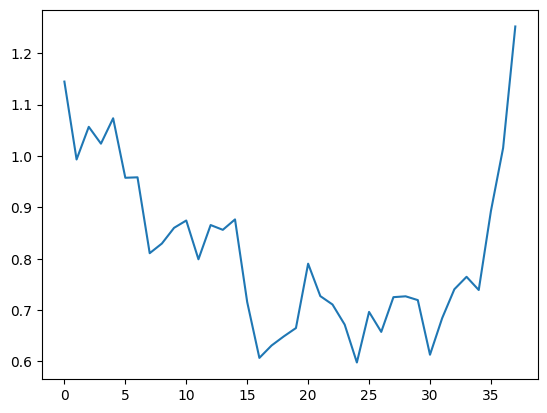

In [12]:
import matplotlib.pyplot as plt
plt.plot(cum_returns)
plt.show()